# Mean-performance numbers: is the mean degraded by the uncertainty heads? (pr_classic7_mse_sel)

REPORTING notebook: produces the numbers to quote, no figures. Deliberately thin on markdown (the logic lives in `src/evaluation/benchmark_summary.py`). **Same code as `canal1_classic_aleatoric.ipynb`**, only the paths change (`RUN_ID`, `PROJ`, figure name) -- same `msemeanonly` baseline, same machinery, same cutoffs.

**log1p(CP10k) axis only**: the `*_raw` models are excluded (log1p(raw counts) axis, separate table). Beta-NLL sweep reduced to `lambda = 0.0` (the pure NLL). Both estimators are reported: **B** = `pearson` = `g*` (predictive mean of the transform) and **A** = `pearson_logmean` = `log1p(mu/delta)` (mean only) -- count models only.

## What `pr_classic7_mse_sel` is

**Second sensitivity arm on `early_stop_criterion`**, paired against `pr_classic3` exactly as `pr_classic4_vloss_v1` was. One single variable: the epoch selection rule, `corr` → **`mse`** -- the validation MSE taken **on the axis where the correlation is reported** (key `mse_corr_axis`: option A `log1p(mu/depth_scale)` vs `log1p(y/depth_scale)` for the count models, the native target otherwise). Everything else is `pr_classic3` to the letter: v5, r75, hvg_top3000, `lopo_next_val`, seed 42, same production depths 25000 / 10000 / 10000, deferred chain.

**Why a second arm, when `pr_classic4` already moved this knob.** `corr` against `val_loss` is **circular on the correlation axis**: each criterion wins on its own metric, so the 3 to 77 % reshuffle that `pr_classic4` produced bounds nothing about the models. `mse` is a **third axis**, the objective of neither contender, and it means the same thing for the run's 14 model types (by construction of `mse_corr_axis`). Two readings: a ranking that survives it is not an artifact of the selection rule; and since MSE is *mean-only*, the `corr − mse` gap isolates how much each variance head's epoch choice was driven by its variance output rather than by its mean.

**Two free internal controls.** `msemeanonly`: its loss **is** its MSE, so `mse` and `val_loss` must pick the same epoch there. `homoscedastic`: already known to be nearly insensitive to the criterion, its `log_var` being constant per gene.

> ⚠️ **The run's 4 `*_cp_nr` heads are excluded from here** (as in `pr_classic3`, which has none). They have no twin in `pr_classic3`: their `corr` reference at the production depth is `pr_classic6` for TLS + LUNG_CANCER and `pr_classic5` for 10x_TuPro. That is a separate comparison, to be done in its own notebook.

In [8]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

# benchmark_summary.py is edited alongside this notebook, and a kernel that already imported it
# keeps the module object cached, so a new function would stay invisible and raise NameError.
# Reloading here makes re-running this cell enough; no kernel restart needed.
import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, format_headline_registry,
    cutoff_donor_points, paired_donor_deltas, paired_deltas_full, estimator_gap,
    REGISTRY_METRICS,
)

RUN_ID    = "pr_classic7_mse_sel"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
REFERENCE = "msemeanonly"                      # the mean-only baseline the section argues against
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel
METRICS   = ("pearson", "pearson_logmean")     # B, then A (A exists for count models only)

# log1p(CP10k) axis ONLY. The depth-blind *_raw pair reports on log1p(raw counts) and must never
# share a table or an axis with these; it gets its own report block when needed.
# The last two exist under pr_classic1 as well, so all three runs carry them and a
#          three-way comparison IS available.
CP_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
             "poisson_cp", "negativebinomial_hetero_noanchor_cp",
             "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]

summaries = discover_run_summaries(PROJ / "results", RUN_ID, DATASETS,
                                   radius=RADIUS, models=CP_MODELS, lambda_keep=0.0)
print(f"{len(summaries)} runs loaded")
for s in summaries:
    print(f"   {s['dataset']:<12s} {s['label']}")

# Without the baseline every delta cell below silently produces empty tables, so fail here
# instead -- most likely cause is that canal1 has not yet written benchmark_summary.parquet.
_found = {s["label"].split("|")[0] for s in summaries}
assert REFERENCE in _found, (
    f"reference {REFERENCE!r} missing from the loaded runs ({sorted(_found)}). "
    f"did canal1 run on this model?")
_missing = [m for m in CP_MODELS if m not in _found]
if _missing:
    print(f"\n(!) models requested but not found: {_missing}")

24 runs loaded
   10x_TuPro    heteroscedastic|lam0.0
   10x_TuPro    homoscedastic|lam0.0
   10x_TuPro    msemeanonly
   10x_TuPro    negativebinomial_genedisp_cp
   10x_TuPro    negativebinomial_hetero_noanchor_cp
   10x_TuPro    negativebinomial_spotdisp_cp
   10x_TuPro    poisson_cp
   10x_TuPro    spot_homoscedastic|lam0.0
   TLS          heteroscedastic|lam0.0
   TLS          homoscedastic|lam0.0
   TLS          msemeanonly
   TLS          negativebinomial_genedisp_cp
   TLS          negativebinomial_hetero_noanchor_cp
   TLS          negativebinomial_spotdisp_cp
   TLS          poisson_cp
   TLS          spot_homoscedastic|lam0.0
   LUNG_CANCER  heteroscedastic|lam0.0
   LUNG_CANCER  homoscedastic|lam0.0
   LUNG_CANCER  msemeanonly
   LUNG_CANCER  negativebinomial_genedisp_cp
   LUNG_CANCER  negativebinomial_hetero_noanchor_cp
   LUNG_CANCER  negativebinomial_spotdisp_cp
   LUNG_CANCER  poisson_cp
   LUNG_CANCER  spot_homoscedastic|lam0.0


In [9]:
# Headline: full shared gene panel, every available uncertainty + the K raw per-donor points.
# The COMPLETE registry rather than just the two correlation estimators: disp_signed / ece_pit /
# var_residual_corr are already in it, and the last cell needs disp_signed for the two new heads.
stats_headline, donor_points = headline_registry(summaries, metrics=REGISTRY_METRICS)
print(format_headline_registry(stats_headline, datasets=DATASETS, metrics=REGISTRY_METRICS))

for ds in DATASETS:
    sub = donor_points[(donor_points["dataset"] == ds) & (donor_points["metric"] == "pearson")]
    if not sub.empty:
        print(f"\n-- per-donor points (B), {ds} --")
        print(sub.pivot_table(index="model", columns="donor", values="value").round(4).to_string())

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | pearson  (K=7 donors, N=3000 genes) ---
  heteroscedastic|lam0.0                     +0.1659  SE 0.0139  t-CI [+0.1318,+0.2000] (df 6, t* 2.45)  PI-new-donor [+0.0695,+0.2622]  gene-boot [+0.1612,+0.1703] (SE 0.0024)
  negativebinomial_spotdisp_cp               +0.1620  SE 0.0121  t-CI [+0.1324,+0.1916] (df 

In [10]:
# Paired deltas vs the baseline: ALL cutoffs, THREE uncertainty readings.
# D = mat_model - mat_reference (genes x donors) is built ONCE per (model, metric, cutoff) and then
# collapsed either way, so the three readings describe the SAME quantity (identical point estimate)
# and differ only in what is resampled:
#   t-CI / SEM  collapse over GENES  -> K donor deltas -> patients resampled  <- THE headline bar
#   boot-gene   collapse over DONORS -> N gene deltas  -> genes resampled, donor cohort FIXED
# NOTE: only metric B appears here. A = pearson_logmean exists for COUNT models only, so a delta in
# A against the mean-only baseline is UNDEFINED (the baseline has no A). The A-vs-B question is the
# within-model Jensen gap, computed two cells down.
deltas = paired_deltas_full(summaries, reference=REFERENCE, metrics=METRICS, ns=NS)
print(f"{len(deltas)} deltas (dataset x metric x cutoff x model)")

LABEL = {"pearson": "B = g* = E[log1p(Y/delta)]", "pearson_logmean": "A = log1p(mu/delta), mean-only"}

for ds in DATASETS:
    for m in METRICS:
        sub = deltas[(deltas["dataset"] == ds) & (deltas["metric"] == m)]
        if sub.empty:
            continue
        print(f"\n=== {ds} | {LABEL[m]} | delta vs {REFERENCE} ===")
        base = sub.drop_duplicates("n").set_index("n")["reference_mean"]
        print("   base :  " + "   ".join(f"n={int(k)}: {v:+.4f}" for k, v in base.items()))

        # (a) the effect. '*' = donor Student-t CI excludes 0 (the claim that matters);
        #     'o' = gene-bootstrap CI excludes 0 (gene-panel stable, says nothing about a new patient).
        cells = [f"{r.delta_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
                 f"{'o' if r.excludes_zero_gene else ' '}" for r in sub.itertuples()]
        print(sub.assign(c=cells).pivot_table(index="model", columns="n",
                                              values="c", aggfunc="first").to_string())

        # (b) the three half-widths side by side: t-CI / 1 SEM / gene-bootstrap.
        w = [f"{(r.delta_ci_hi - r.delta_ci_lo) / 2:.4f}/{r.delta_sem:.4f}/"
             f"{(r.gene_ci_hi - r.gene_ci_lo) / 2:.4f}" for r in sub.itertuples()]
        print("\n   half-widths  t-CI / SEM / boot-gene :")
        print(sub.assign(c=w).pivot_table(index="model", columns="n",
                                          values="c", aggfunc="first").to_string())

126 deltas (dataset x metric x cutoff x model)

=== 10x_TuPro | B = g* = E[log1p(Y/delta)] | delta vs msemeanonly ===
   base :  n=50: +0.5208   n=100: +0.4830   n=500: +0.3705   n=1000: +0.3083   n=2000: +0.2237   n=3000: +0.1577
n                                         50         100        500        1000       2000       3000
model                                                                                                
heteroscedastic|lam0.0               +0.0141 o  +0.0153 o  +0.0118 o  +0.0116 o  +0.0104 o  +0.0082 o
homoscedastic|lam0.0                 +0.0177 o  +0.0151 o  +0.0082 o  +0.0069 o  +0.0056 o  +0.0038 o
negativebinomial_genedisp_cp         +0.0089    +0.0090 o  +0.0047 o  +0.0005    -0.0049 o  -0.0057 o
negativebinomial_hetero_noanchor_cp  +0.0084    +0.0065    -0.0021    -0.0049 o  -0.0031 o  -0.0010  
negativebinomial_spotdisp_cp         -0.0095    -0.0101 o  -0.0083 o  -0.0040 o  +0.0026 o  +0.0043 o
poisson_cp                           +0.0196 o  +0.0198

In [11]:
# The DETECTED effects only -- the ones a sentence in the paper may name.
hits = deltas[deltas["excludes_zero_t"]].sort_values(["dataset", "n", "delta_mean"])
print(f"=== DETECTED effects: donor CI on the difference excluding 0  ({len(hits)} / {len(deltas)}) ===")
for r in hits.itertuples():
    print(f"{r.dataset:<12s} n={r.n:<5d} {r.model:<40s} "
          f"delta {r.delta_mean:+.4f} [{r.delta_ci_lo:+.4f},{r.delta_ci_hi:+.4f}]  "
          f"donors {r.n_donors_better}+/{r.n_donors_worse}-")

# Equivalence bound PER CUTOFF. Reporting a single bound over all cutoffs would be dominated by
# n=50, where the CIs are widest (few genes) -- that says "we cannot see anything at n=50", not
# "the models are equivalent". The bound only means something at a stated n.
print("\n=== equivalence bound per cutoff (worst CI lower bound, NOT detected models) ===")
safe = deltas[~deltas["excludes_zero_t"]]
for ds in DATASETS:
    g_ds = safe[safe["dataset"] == ds]
    if g_ds.empty:
        continue
    parts = []
    for n, g in g_ds.groupby("n", sort=True):
        w = g.loc[g["delta_ci_lo"].idxmin()]
        parts.append(f"n={int(n)}: {w['delta_ci_lo']:+.4f}")
    print(f"{ds:<12s} " + "   ".join(parts))

# Which models are never detected anywhere: the clean equivalence claims.
print("\n=== models never detected (equivalent to the baseline at every cutoff) ===")
for ds in DATASETS:
    d_ds = deltas[deltas["dataset"] == ds]
    never = sorted(set(d_ds["model"]) - set(d_ds[d_ds["excludes_zero_t"]]["model"]))
    print(f"{ds:<12s} {', '.join(never) if never else '(none)'}")

=== DETECTED effects: donor CI on the difference excluding 0  (5 / 126) ===
LUNG_CANCER  n=50    negativebinomial_spotdisp_cp             delta -0.0436 [-0.0639,-0.0232]  donors 0+/8-
LUNG_CANCER  n=100   negativebinomial_spotdisp_cp             delta -0.0404 [-0.0595,-0.0214]  donors 0+/8-
LUNG_CANCER  n=500   negativebinomial_spotdisp_cp             delta -0.0212 [-0.0398,-0.0025]  donors 1+/7-
TLS          n=50    homoscedastic|lam0.0                     delta -0.0049 [-0.0090,-0.0008]  donors 1+/5-
TLS          n=100   homoscedastic|lam0.0                     delta -0.0032 [-0.0065,-0.0000]  donors 1+/5-

=== equivalence bound per cutoff (worst CI lower bound, NOT detected models) ===
10x_TuPro    n=50: -0.0702   n=100: -0.0692   n=500: -0.0535   n=1000: -0.0433   n=2000: -0.0301   n=3000: -0.0247
TLS          n=50: -0.1454   n=100: -0.1117   n=500: -0.0762   n=1000: -0.0650   n=2000: -0.0447   n=3000: -0.0318
LUNG_CANCER  n=50: -0.0476   n=100: -0.0524   n=500: -0.0564   n=1000: -

In [12]:
# A vs B: the JENSEN GAP, within each count model (the only place A is defined).
# gap = B - A per (gene, donor), collapsed the same two ways. Positive = routing the prediction
# through the full fitted predictive (mu AND alpha) beats using the mean alone.
from src.evaluation.benchmark_summary import estimator_gap

gaps = estimator_gap(summaries, metric_b="pearson", metric_a="pearson_logmean", ns=NS)
print(f"{len(gaps)} gaps (dataset x cutoff x count model)\n")

for ds in DATASETS:
    sub = gaps[gaps["dataset"] == ds]
    if sub.empty:
        continue
    print(f"=== {ds} | gap B - A ('*' donor CI excludes 0, 'o' boot-gene excludes 0) ===")
    cells = [f"{r.gap_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
             f"{'o' if r.excludes_zero_gene else ' '}" for r in sub.itertuples()]
    print(sub.assign(c=cells).pivot_table(index="model", columns="n",
                                          values="c", aggfunc="first").to_string())
    w = [f"{(r.gap_ci_hi - r.gap_ci_lo) / 2:.4f}/{r.gap_sem:.4f}/"
         f"{(r.gene_ci_hi - r.gene_ci_lo) / 2:.4f}" for r in sub.itertuples()]
    print("\n   half-widths  t-CI / SEM / boot-gene :")
    print(sub.assign(c=w).pivot_table(index="model", columns="n",
                                      values="c", aggfunc="first").to_string())
    print()

72 gaps (dataset x cutoff x count model)

=== 10x_TuPro | gap B - A ('*' donor CI excludes 0, 'o' boot-gene excludes 0) ===
n                                         50         100        500        1000       2000       3000
model                                                                                                
negativebinomial_genedisp_cp         +0.0002 o  +0.0001    +0.0000    -0.0001 o  -0.0001 o  -0.0001 o
negativebinomial_hetero_noanchor_cp  +0.0074 o  +0.0030    -0.0035 o  -0.0023 o  +0.0052 o  +0.0069 o
negativebinomial_spotdisp_cp         -0.0252*o  -0.0259*o  -0.0182 o  -0.0118 o  -0.0010    +0.0019 o
poisson_cp                           +0.0002 o  +0.0001    +0.0000    -0.0001 o  -0.0001 o  -0.0001 o

   half-widths  t-CI / SEM / boot-gene :
n                                                    50                    100                   500                   1000                  2000                  3000
model                                                 

written: fig_mean_performance_pr_classic7_mse_sel.pdf


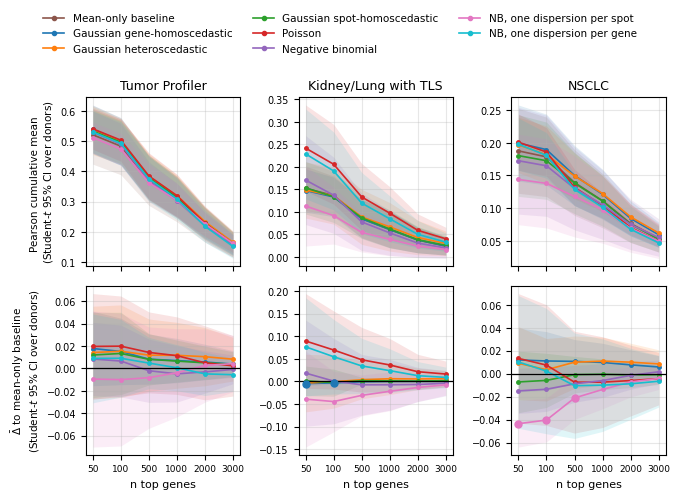

In [13]:
# FIGURE fig:mean-performance -- 2 rows x 3 datasets.
#   top    absolute cumulative Pearson (B), donor Student-t 95% CI
#   bottom PAIRED delta vs the mean-only baseline, same CI family
# The bottom row exists because on the top row the curves are visually superimposed: the effects
# discussed in the text (0.005-0.036) are invisible at a 0-0.55 scale. The baseline IS the zero
# line below, so nothing is lost by dropping it from that row.
#
# SIZED FOR A PORTRAIT PAGE. Drawn at roughly its printed size (~6.9 in for a ~6.3 in textwidth),
# NOT larger: a wide figure shrunk by \includegraphics[width=\textwidth] has its fonts shrunk by
# the same factor and becomes unreadable. The legend sits ABOVE rather than beside, because in
# portrait the scarce resource is width, not height; and there is no suptitle, which would only
# duplicate the LaTeX caption.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from src.evaluation.benchmark_summary import donor_lopo_stats

# Canonical model -> color map, keyed on model_type (NOT the |lam label): a positional scheme
# silently recolors a model when the loaded set changes.
# One color per model_type, everywhere. The two restricted-dispersion NB heads take the next
# free tab10 slots (C6 pink, C9 cyan).
MODEL_COLORS = {
    "msemeanonly":                         "#8c564b",   # brown  -- the mean-only baseline
    "homoscedastic":                       "#1f77b4",   # blue
    "heteroscedastic":                     "#ff7f0e",   # orange
    "spot_homoscedastic":                  "#2ca02c",   # green
    "poisson_cp":                          "#d62728",   # red    -- Poisson family
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple -- NB family, free dispersion
    "negativebinomial_spotdisp_cp":        "#e377c2",   # pink   -- NB, one dispersion per spot
    "negativebinomial_genedisp_cp":        "#17becf",   # cyan   -- NB, one dispersion per gene
}
# Display names. The internal model_type carries implementation detail (_cp, _hetero_noanchor,
# |lam0.0) that means nothing to a reader; these match the wording of the overview section.
# Note: the two restricted-dispersion heads are NOT the count analogues of the
# Gaussian homoscedastic / spot-homoscedastic heads. Constraining the dispersion does not make the
# predictive variance constant -- NB var = mu + alpha*mu^2 still varies through mu -- so they
# restrict WHERE the overdispersion may come from, not whether the variance is input-dependent.
MODEL_LABELS = {
    "msemeanonly":                         "Mean-only baseline",
    "homoscedastic":                       "Gaussian gene-homoscedastic",
    "heteroscedastic":                     "Gaussian heteroscedastic",
    "spot_homoscedastic":                  "Gaussian spot-homoscedastic",
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "Negative binomial",
    "negativebinomial_spotdisp_cp":        "NB, one dispersion per spot",
    "negativebinomial_genedisp_cp":        "NB, one dispersion per gene",
}
MODEL_ORDER = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp",
               "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]
DATASET_LABELS = {"10x_TuPro":   "Tumor Profiler",
                  "TLS":         "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

def _mt(label): return label.split("|")[0]

# Top row: per-model cumulative curve + donor t-CI. Rebuilt from cutoff_donor_points, which applies
# the SAME gene ordering as paired_deltas_full, so the two rows of the figure cannot drift apart.
points = cutoff_donor_points(summaries, ns=NS, metrics=("pearson",))
rows = []
for (ds, model, n), g in points.groupby(["dataset", "model", "n"]):
    st = donor_lopo_stats(dict(zip(g["donor"], g["value"])))
    rows.append(dict(dataset=ds, model=model, n=n, mean=st["mean"],
                     lo=st["ci95_mean"][0], hi=st["ci95_mean"][1]))
curves = pd.DataFrame(rows)

NS_PLOT = sorted(curves["n"].unique())
x = np.arange(len(NS_PLOT))
fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.9, 5.0), sharex=True)

for j, ds in enumerate(DATASETS):
    top, bot = axes[0, j], axes[1, j]
    present = set(curves.loc[curves["dataset"] == ds, "model"])
    for mt in MODEL_ORDER:                                   # fixed order -> stable colors/legend
        model = next((m for m in present if _mt(m) == mt), None)
        if model is None:
            continue
        c = MODEL_COLORS[mt]
        cur = (curves[(curves["dataset"] == ds) & (curves["model"] == model)]
               .set_index("n").reindex(NS_PLOT))
        top.fill_between(x, cur["lo"], cur["hi"], color=c, alpha=0.13, linewidth=0)
        top.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color=c)

        d = deltas[(deltas["dataset"] == ds) & (deltas["metric"] == "pearson")
                   & (deltas["model"] == model)]
        if d.empty:
            continue                      # the reference itself: it IS the zero line below
        d = d.set_index("n").reindex(NS_PLOT)
        bot.fill_between(x, d["delta_ci_lo"], d["delta_ci_hi"], color=c, alpha=0.13, linewidth=0)
        bot.plot(x, d["delta_mean"], "-o", ms=2.5, lw=1.2, color=c)
        # filled larger marker where the donor CI excludes 0 (the only points the text names)
        det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
        bot.plot(x[det], d["delta_mean"].to_numpy()[det], "o", ms=5, color=c, zorder=5)

    bot.axhline(0, color="black", lw=0.9)
    top.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    for ax in (top, bot):
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    bot.set_xticks(x)
    bot.set_xticklabels([str(n) for n in NS_PLOT], fontsize=6.5)
    bot.set_xlabel("n top genes", fontsize=8)

axes[0, 0].set_ylabel("Pearson cumulative mean \n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)
axes[1, 0].set_ylabel("$\\bar{\\Delta}$ to mean-only baseline\n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)

handles = [Line2D([0], [0], color=MODEL_COLORS[mt], marker="o", ms=3, lw=1.2,
                  label=MODEL_LABELS[mt]) for mt in MODEL_ORDER]
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=3, frameon=False, fontsize=7.5)

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
FIG_DIR = PROJ / "results" / "_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_mean_performance_pr_classic7_mse_sel.{ext}", dpi=300, bbox_inches="tight")
print("written:", "fig_mean_performance_pr_classic7_mse_sel.pdf")
plt.show()